# Wrist activity recognition trained on men, women or both

Does the sex of the people a wrist activity classifier is trained on change how well it works for women and for men?

**Data.** CAPTURE-24 (Chan et al. 2024, *Scientific Data* 11, [doi:10.1038/s41597-024-03960-3](https://doi.org/10.1038/s41597-024-03960-3); data on the [Oxford Research Archive](https://ora.ox.ac.uk/objects/uuid:99d7c092-d865-4a19-b096-cc16440cd001), CC BY 4.0): 151 adults (99 women, 52 men) wore an Axivity AX3 accelerometer on the wrist for about 24 hours (100 Hz, three axes). Activities were annotated from a wearable camera and a sleep diary. Age is given in four bands and sex as female or male; nothing is known about the menstrual cycle or hormonal contraception. Download with `python download_cycle_data.py capture24` or set `CAPTURE24` to the path of `capture24.zip`.

1. **Windows and features.** 10 s windows labelled with the four classes of Walmsley et al. 2020 (sleep, sedentary, light, moderate to vigorous), 32 features per window.
2. **Design.** In each of 50 random splits, 12 men and 12 women of the same age bands are held out for testing. Three classifiers are trained on 40 people each: 40 men, 40 women of the same age bands, or 20 of each.
3. **Outcome.** Macro F1 for each test participant, and the difference between the classifier trained on the participant's own sex and the one trained on the other sex.

Features are cached in `results/capture24/` and each split in `results/capture24/runs/`, so the notebook only computes what is missing when it is run again.

In [1]:
import os, io, json, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score
from IPython.display import Image, display
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

REPO_DIR = Path.cwd()  # run the notebook from the repository folder
ZIP = Path(os.environ.get("CAPTURE24", "data/capture24/capture24.zip"))
FIG_DIR, RES_DIR = REPO_DIR / "figures", REPO_DIR / "results"
CACHE_DIR = RES_DIR / "capture24"
RUN_DIR = CACHE_DIR / "runs"
for d in (FIG_DIR, RUN_DIR):
    d.mkdir(parents=True, exist_ok=True)

FS = 100                       # Hz
WIN = 10 * FS                  # 10 s windows
CLASSES = ["sleep", "sedentary", "light", "moderate-vigorous"]
N_SPLITS = 50
N_TEST, N_TRAIN = 12, 40       # per sex in the test set; people per training set
N_PER_PERSON = 1500            # training windows drawn per person
CACHE_VERSION = 1
SEED = 7

BLUE, ORANGE, INK, INK2, MUTED, GRIDLINE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#8c8b86", "#e4e3de"


def setup():
    import logging
    from matplotlib import font_manager as fm
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
    avail = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ["Calibri", "Carlito", "Segoe UI", "Arial"] if f in avail), "DejaVu Sans")
    plt.rcParams.update({
        "font.family": fam, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
        "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
        "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRIDLINE, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
        "lines.linewidth": 1.6, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
        "figure.facecolor": "white", "axes.facecolor": "white"})


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=str(path), width=900))
    print("saved", path.relative_to(REPO_DIR))


setup()

## Participants

In [2]:
Z = zipfile.ZipFile(ZIP)
meta = pd.read_csv(Z.open("capture24/metadata.csv"))
labels = pd.read_csv(Z.open("capture24/annotation-label-dictionary.csv")).set_index("annotation")["label:Walmsley2020"]
BAND = meta.set_index("pid").age
SEX = meta.set_index("pid").sex
print(f"{len(meta)} participants: {int((meta.sex == 'F').sum())} women, {int((meta.sex == 'M').sum())} men")
print(pd.crosstab(meta.age, meta.sex).to_string())

151 participants: 99 women, 52 men
sex     F   M
age          
18-29  26  17
30-37  25  12
38-52  30   7
53+    18  16


## Windows and features

The signal is cut into non-overlapping 10 s windows. Each window takes the most frequent label among its samples; windows without a label, or with missing samples, are left out. The 32 features are computed from the three axes and the vector magnitude: magnitude statistics (mean, standard deviation, minimum, maximum, five percentiles, mean of the magnitude above 1 g, mean absolute change), mean and standard deviation of each axis, correlation between axes, mean and spread of the wrist angles, and the spectrum of the magnitude between 0.3 and 15 Hz (dominant frequency and its share of power, power in four bands, spectral entropy, total power) and its autocorrelation at 1 s.

In [3]:
FEATURES = (["m_mean", "m_std", "m_min", "m_max", "m_p10", "m_p25", "m_p50", "m_p75", "m_p90", "enmo", "jerk"]
            + [f"{a}_{s}" for a in "xyz" for s in ("mean", "std")] + ["corr_xy", "corr_xz", "corr_yz"]
            + ["pitch_mean", "pitch_std", "roll_mean", "dom_freq", "dom_share"]
            + ["pow_0.3_1", "pow_1_3", "pow_3_5", "pow_5_15", "spec_entropy", "log_power", "acf_1s"])
F_SPEC = np.fft.rfftfreq(WIN, 1 / FS)
SPEC = (F_SPEC >= 0.3) & (F_SPEC <= 15)
HANN = np.hanning(WIN)


def features(xyz):
    """32 features for each window; xyz has shape (windows, samples, 3), in g."""
    x, y, z = xyz[..., 0], xyz[..., 1], xyz[..., 2]
    m = np.sqrt(x ** 2 + y ** 2 + z ** 2)
    q = np.percentile(m, [10, 25, 50, 75, 90], axis=1)
    out = [m.mean(1), m.std(1), m.min(1), m.max(1), *q, np.clip(m - 1, 0, None).mean(1), np.abs(np.diff(m, axis=1)).mean(1) * FS]
    for a in (x, y, z):
        out += [a.mean(1), a.std(1)]
    dev = [a - a.mean(1, keepdims=True) for a in (x, y, z)]
    sd = [d.std(1) + 1e-9 for d in dev]
    out += [(dev[i] * dev[j]).mean(1) / (sd[i] * sd[j]) for i, j in ((0, 1), (0, 2), (1, 2))]
    pitch = np.degrees(np.arctan2(-x, np.sqrt(y ** 2 + z ** 2)))
    roll = np.arctan2(y, z)
    out += [pitch.mean(1), pitch.std(1), np.degrees(np.arctan2(np.sin(roll).mean(1), np.cos(roll).mean(1)))]
    mc = m - m.mean(1, keepdims=True)
    P = np.abs(np.fft.rfft(mc * HANN, axis=1)) ** 2
    tot = P[:, SPEC].sum(1) + 1e-12
    out += [F_SPEC[SPEC][P[:, SPEC].argmax(1)], P[:, SPEC].max(1) / tot]
    out += [P[:, (F_SPEC >= lo) & (F_SPEC < hi)].sum(1) / tot for lo, hi in ((0.3, 1), (1, 3), (3, 5), (5, 15))]
    p = P[:, SPEC] / tot[:, None]
    out += [-(p * np.log(p + 1e-12)).sum(1) / np.log(SPEC.sum()), np.log10(tot)]
    out += [(mc[:, :-FS] * mc[:, FS:]).mean(1) / (mc.var(1) + 1e-12)]
    return np.stack(out, 1).astype(np.float32)


def participant(pid):
    """Features and labels of the labelled windows of one participant."""
    with Z.open(f"capture24/{pid}.csv.gz") as fh:
        df = pd.read_csv(io.BytesIO(fh.read()), compression="gzip", usecols=["x", "y", "z", "annotation"],
                         dtype={"x": "float32", "y": "float32", "z": "float32", "annotation": "category"})
    cls = df.annotation.cat.categories.map(lambda a: CLASSES.index(labels[a]) if a in labels.index else -1)
    lab = np.where(df.annotation.cat.codes.values >= 0, np.asarray(cls)[df.annotation.cat.codes.values], -1)
    n = len(df) // WIN
    lab = lab[: n * WIN].reshape(n, WIN)
    counts = np.stack([(lab == k).sum(1) for k in range(-1, len(CLASSES))], 1)
    y = counts.argmax(1) - 1
    xyz = df[["x", "y", "z"]].values[: n * WIN].reshape(n, WIN, 3)
    ok = (y >= 0) & np.isfinite(xyz).all((1, 2))
    X = np.concatenate([features(xyz[i:i + 2000][ok[i:i + 2000]]) for i in range(0, n, 2000)])
    return X, y[ok].astype(np.int8), n


def cached_participant(pid):
    path = CACHE_DIR / f"{pid}.npz"
    if path.exists():
        z = np.load(path)
        if int(z["version"]) == CACHE_VERSION:
            return z["X"], z["y"], int(z["n_windows"])
    X, y, n = participant(pid)
    np.savez_compressed(path, version=CACHE_VERSION, X=X, y=y, n_windows=n)
    return X, y, n

## Check: labelled time

Number of labelled windows per participant and the annotated hours in each class, by sex.

In [4]:
D = {pid: cached_participant(pid) for pid in meta.pid}
W = pd.DataFrame([dict(pid=p, sex=SEX[p], windows=D[p][2], labelled=len(D[p][1]),
                       **{c: (D[p][1] == k).sum() * 10 / 3600 for k, c in enumerate(CLASSES)}) for p in meta.pid])
print(f"labelled windows per participant: median {W.labelled.median():.0f} of {W.windows.median():.0f} "
      f"({(W.labelled / W.windows).median():.0%}), minimum {W.labelled.min()}")
print("annotated hours per participant, median by sex:")
print(W.groupby("sex")[CLASSES].median().round(2).to_string())
print("participants with no moderate to vigorous windows:", int((W["moderate-vigorous"] == 0).sum()))

labelled windows per participant: median 6139 of 9390 (68%), minimum 2189
annotated hours per participant, median by sex:
     sleep  sedentary  light  moderate-vigorous
sex                                            
F     6.83       6.44   2.99               0.49
M     5.46       7.25   2.55               0.60
participants with no moderate to vigorous windows: 16


## Splits and classifiers

For each split: 12 men are drawn at random for testing and the other 40 men form the male training set. Women are then drawn to match the age bands of those men, 12 for testing and 40 for training, so the test and training sets have the same age bands in both sexes. The mixed training set takes 20 of the training men and 20 training women of the same age bands. Each classifier is a gradient-boosted tree model (scikit-learn `HistGradientBoostingClassifier`, classes weighted by their inverse frequency) trained on 1500 random windows per person. Each test participant is scored on all of her or his labelled windows, with the macro F1 over the classes that participant has.

In [5]:
def matched(ref, pool, rng):
    """Draw, without replacement from pool, one person in the same age band for each person in ref."""
    out = []
    for b, k in BAND[list(ref)].value_counts().sort_index().items():
        out += list(rng.choice([p for p in pool if BAND[p] == b], k, replace=False))
    return np.array(out)


def make_split(r):
    rng = np.random.default_rng(SEED + r)
    men, women = meta.pid[meta.sex == "M"].values, meta.pid[meta.sex == "F"].values
    m_test = rng.choice(men, N_TEST, replace=False)
    m_train = np.setdiff1d(men, m_test)[: N_TRAIN]
    f_test = matched(m_test, women, rng)
    f_train = matched(m_train, np.setdiff1d(women, f_test), rng)
    mx_m = rng.choice(m_train, N_TRAIN // 2, replace=False)
    mixed = np.concatenate([mx_m, matched(mx_m, f_train, rng)])
    return rng, dict(men=m_train, women=f_train, mixed=mixed), np.concatenate([f_test, m_test])


def train(people, rng):
    X, y = [], []
    for p in people:
        Xp, yp, _ = D[p]
        i = rng.choice(len(yp), min(N_PER_PERSON, len(yp)), replace=False)
        X.append(Xp[i]); y.append(yp[i])
    X, y = np.concatenate(X), np.concatenate(y)
    clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, class_weight="balanced",
                                         early_stopping=False, random_state=int(rng.integers(1 << 31)))
    return clf.fit(X, y)


def run_split(r):
    path = RUN_DIR / f"split_{r:02d}.csv"
    if path.exists():
        return pd.read_csv(path)
    rng, sets, test = make_split(r)
    rows = []
    for name, people in sets.items():
        clf = train(people, rng)
        for p in test:
            Xp, yp, _ = D[p]
            pred = clf.predict(Xp)
            present = np.unique(yp)
            f1 = f1_score(yp, pred, labels=list(range(len(CLASSES))), average=None, zero_division=0)
            rows.append(dict(split=r, train=name, pid=p, sex=SEX[p], macro_f1=f1[present].mean(), accuracy=(pred == yp).mean(),
                             **{f"f1_{c}": (f1[k] if k in present else np.nan) for k, c in enumerate(CLASSES)}))
    out = pd.DataFrame(rows)
    out.to_csv(path, index=False)
    return out

In [6]:
R = pd.concat([run_split(r) for r in range(N_SPLITS)], ignore_index=True)
print(f"{N_SPLITS} splits, {len(R)} test scores")
print(f"test appearances per person: women median {R[R.sex == 'F'].groupby('pid').split.nunique().median():.0f}, "
      f"men median {R[R.sex == 'M'].groupby('pid').split.nunique().median():.0f}; "
      f"tested at least once: {R[R.sex == 'F'].pid.nunique()} women, {R[R.sex == 'M'].pid.nunique()} men")

50 splits, 3600 test scores
test appearances per person: women median 6, men median 12; tested at least once: 95 women, 52 men


## Results

Scores are first averaged within each test participant over the splits in which she or he was tested, so that each person counts once. Confidence intervals are 95% bootstrap intervals over participants (2000 resamples). The **own-sex difference** is the score of the classifier trained on the participant's own sex minus the score of the classifier trained on the other sex.

In [7]:
rng_b = np.random.default_rng(SEED)


def boot_ci(v, n=2000):
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    means = rng_b.choice(v, (n, len(v)), replace=True).mean(1)
    return float(v.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


PP = R.groupby(["pid", "sex", "train"])[["macro_f1"] + [f"f1_{c}" for c in CLASSES]].mean().reset_index()
TRAINS = ["men", "women", "mixed"]
SCORE = pd.DataFrame([dict(sex=s, train=t, n=int(((PP.sex == s) & (PP.train == t)).sum()),
                           **dict(zip(["mean", "lo", "hi"], boot_ci(PP[(PP.sex == s) & (PP.train == t)].macro_f1))))
                      for s in "FM" for t in TRAINS])
print("macro F1 by test sex and training set:")
print(SCORE.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
sd_between = float(PP[PP.train == "mixed"].macro_f1.std())
print(f"\nspread between people (SD of macro F1, mixed training set): {sd_between:.3f}")

wide = PP.pivot_table(index=["pid", "sex"], columns="train", values=["macro_f1"] + [f"f1_{c}" for c in CLASSES]).reset_index()
OWN = []
for s, own, other in (("F", "women", "men"), ("M", "men", "women")):
    w = wide[wide.sex == s]
    for col in ["macro_f1"] + [f"f1_{c}" for c in CLASSES]:
        d = (w[(col, own)] - w[(col, other)]).dropna()
        m, lo, hi = boot_ci(d)
        OWN.append(dict(sex=s, score=col, n=len(d), diff=m, lo=lo, hi=hi, p_wilcoxon=float(stats.wilcoxon(d).pvalue)))
OWN = pd.DataFrame(OWN)
print("\nown-sex difference (own minus other):")
print(OWN.to_string(index=False, float_format=lambda v: f"{v:.3g}"))
mixed_vs_single = {s: boot_ci((wide[wide.sex == s][("macro_f1", "mixed")]
                               - wide[wide.sex == s][("macro_f1", "men" if s == "F" else "women")]).dropna()) for s in "FM"}
for s, (m, lo, hi) in mixed_vs_single.items():
    print(f"{'women' if s == 'F' else 'men'}: mixed minus other-sex training set, macro F1 {m:+.4f} (95% CI {lo:+.4f} to {hi:+.4f})")

macro F1 by test sex and training set:
sex train  n  mean    lo    hi
  F   men 95 0.672 0.653 0.689
  F women 95 0.676 0.658 0.693
  F mixed 95 0.671 0.653 0.688
  M   men 52 0.667 0.643 0.694
  M women 52 0.668 0.643 0.693
  M mixed 52 0.669 0.646 0.695

spread between people (SD of macro F1, mixed training set): 0.088

own-sex difference (own minus other):
sex                score  n      diff        lo      hi  p_wilcoxon
  F             macro_f1 95   0.00384  -0.00257  0.0107       0.297
  F             f1_sleep 95   0.00685 -0.000234  0.0139      0.0515
  F         f1_sedentary 95  -0.00072  -0.00891 0.00695       0.801
  F             f1_light 95    0.0149   0.00826  0.0218     2.1e-05
  F f1_moderate-vigorous 83  -0.00987   -0.0326  0.0148       0.448
  M             macro_f1 52 -0.000358   -0.0116 0.00988       0.434
  M             f1_sleep 52   0.00684  -0.00306  0.0167       0.308
  M         f1_sedentary 52   0.00218  -0.00743   0.012       0.542
  M             f1_light 5

## Figure

**A** Annotated hours in each class per participant, by sex (lines: medians). **B** Macro F1 of test women and test men for each training set, mean with 95% confidence interval. **C** Own-sex difference in macro F1 for each test participant (dots) with the mean and 95% confidence interval. **D** Own-sex difference for each class and for macro F1.

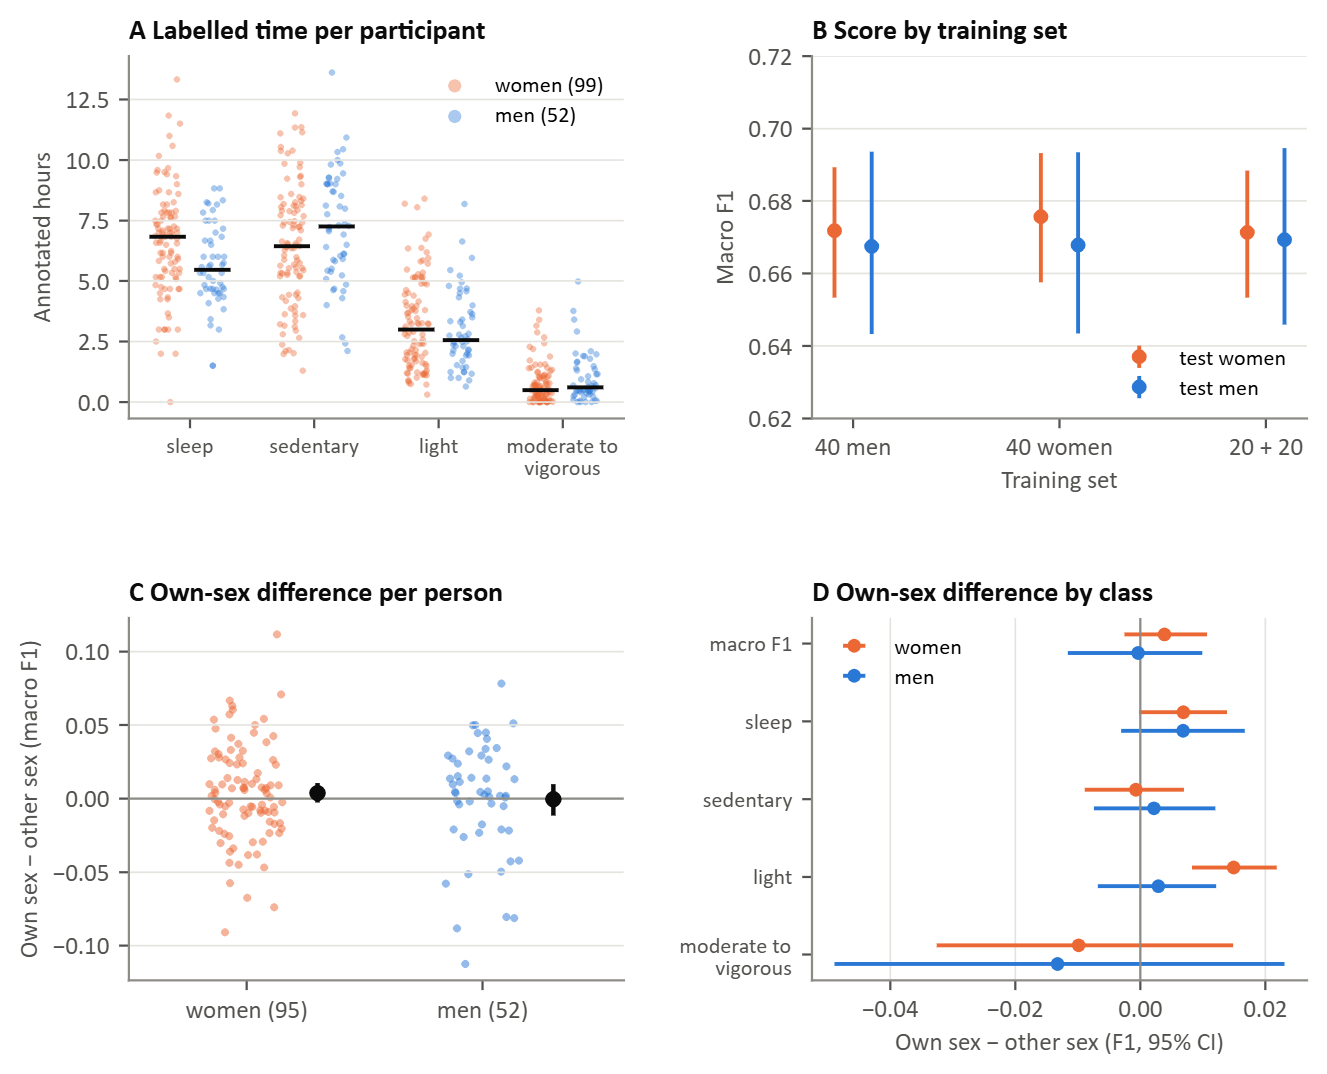

saved figures/activity_training_sex.png


In [8]:
SCOL = {"F": ORANGE, "M": BLUE}
SNAME = {"F": "women", "M": "men"}
SHORT = {"sleep": "sleep", "sedentary": "sedentary", "light": "light", "moderate-vigorous": "moderate to\nvigorous"}
jr = np.random.default_rng(SEED)
fig, ax = plt.subplots(2, 2, figsize=(7.6, 6.0))
fig.subplots_adjust(hspace=0.55, wspace=0.38)

a = ax[0, 0]
for k, c in enumerate(CLASSES):
    for j, s in enumerate("FM"):
        v = W.loc[W.sex == s, c].values
        x0 = k + (j - 0.5) * 0.36
        a.scatter(x0 + jr.uniform(-0.1, 0.1, len(v)), v, s=6, color=SCOL[s], alpha=0.45, lw=0,
                  label=f"{SNAME[s]} ({len(v)})" if k == 0 else None)
        a.plot([x0 - 0.13, x0 + 0.13], [np.median(v)] * 2, color=INK, lw=1.4)
a.set_xticks(range(len(CLASSES)), [SHORT[c] for c in CLASSES], fontsize=8)
a.set(ylabel="Annotated hours", title="A  Labelled time per participant")
a.grid(axis="x", visible=False)
a.legend(loc="upper right", markerscale=2)

a = ax[0, 1]
for j, s in enumerate("FM"):
    d = SCORE[SCORE.sex == s].set_index("train").loc[TRAINS]
    x = np.arange(3) + (j - 0.5) * 0.18
    a.errorbar(x, d["mean"], yerr=[d["mean"] - d.lo, d.hi - d["mean"]], fmt="o", ms=4.5, color=SCOL[s], capsize=0, lw=1.4,
               label=f"test {SNAME[s]}")
a.set_xticks(range(3), ["40 men", "40 women", "20 + 20"])
a.set(xlabel="Training set", ylabel="Macro F1", ylim=(0.62, 0.72), title="B  Score by training set")
a.grid(axis="x", visible=False)
a.legend(loc="lower right")

a = ax[1, 0]
for j, s in enumerate("FM"):
    w = wide[wide.sex == s]
    own, other = ("women", "men") if s == "F" else ("men", "women")
    d = (w[("macro_f1", own)] - w[("macro_f1", other)]).values
    a.scatter(j + jr.uniform(-0.16, 0.16, len(d)), d, s=9, color=SCOL[s], alpha=0.5, lw=0)
    r = OWN[(OWN.sex == s) & (OWN.score == "macro_f1")].iloc[0]
    a.errorbar(j + 0.3, r["diff"], yerr=[[r["diff"] - r.lo], [r.hi - r["diff"]]], fmt="o", ms=5, color=INK, lw=1.6)
a.axhline(0, color=MUTED, lw=0.8)
a.set_xticks([0, 1], [f"women ({int((wide.sex == 'F').sum())})", f"men ({int((wide.sex == 'M').sum())})"])
a.set(xlim=(-0.5, 1.6), ylabel="Own sex − other sex (macro F1)", title="C  Own-sex difference per person")
a.grid(axis="x", visible=False)

a = ax[1, 1]
scores = ["macro_f1"] + [f"f1_{c}" for c in CLASSES]
yy = np.arange(len(scores))[::-1]
for j, s in enumerate("FM"):
    d = OWN[OWN.sex == s].set_index("score").loc[scores]
    y0 = yy + (0.5 - j) * 0.24
    a.errorbar(d["diff"], y0, xerr=[d["diff"] - d.lo, d.hi - d["diff"]], fmt="o", ms=4, color=SCOL[s], lw=1.4,
               label=SNAME[s])
a.axvline(0, color=MUTED, lw=0.8)
a.set_yticks(yy, ["macro F1"] + [SHORT[c] for c in CLASSES], fontsize=8)
a.set(xlabel="Own sex − other sex (F1, 95% CI)", title="D  Own-sex difference by class")
a.grid(axis="y", visible=False)
a.legend(loc="upper left")
save(fig, "activity_training_sex.png")

## Results file

In [9]:
def clean(v):
    if isinstance(v, (np.floating, float)):
        return None if np.isnan(v) else float(f"{float(v):.4g}")
    if isinstance(v, np.integer):
        return int(v)
    return v


RES = {
    "dataset": "CAPTURE-24", "n_participants": len(meta), "n_women": int((meta.sex == "F").sum()), "n_men": int((meta.sex == "M").sum()),
    "splits": N_SPLITS, "test_per_sex": N_TEST, "train_size": N_TRAIN, "windows_per_person_train": N_PER_PERSON,
    "tested_at_least_once": {"F": int(R[R.sex == "F"].pid.nunique()), "M": int(R[R.sex == "M"].pid.nunique())},
    "labelled_windows_median": clean(W.labelled.median()),
    "hours_median_by_sex": {s: {c: clean(W.loc[W.sex == s, c].median()) for c in CLASSES} for s in "FM"},
    "macro_f1": [{k: clean(v) for k, v in r.items()} for r in SCORE.to_dict("records")],
    "sd_between_people": clean(sd_between),
    "own_sex_difference": [{k: clean(v) for k, v in r.items()} for r in OWN.to_dict("records")],
    "mixed_minus_other_sex": {s: [clean(x) for x in v] for s, v in mixed_vs_single.items()},
}
(RES_DIR / "activity_training_sex.json").write_text(json.dumps(RES, indent=1))
print("saved results/activity_training_sex.json")

saved results/activity_training_sex.json
